# 2.6 — Geographic Regional Analysis

Tests whether the portrait→landscape shift in tablet morphology across the
2nd→1st millennium transition is a **universal production-practice change**
or a **compositional sampling artifact** (driven by the corpus suddenly
containing far more tablets from landscape-dominated sites, particularly Uruk).

## Analytical design

**Layer 1 — Regional variance decomposition**  
Decompose the overall 2nd→1st millennium h/w ratio shift into a within-region
component (each region's own shift × its weight) and a between-region
compositional component (corpus composition shifted toward regions that were
already more landscape-oriented).  
If within-region dominates → trend is real. If compositional dominates → sampling artifact.

**Layer 2 — Genre-controlled within-region comparison**  
For each region, compare Administrative tablets only between 2nd and 1st millennium
(Mann-Whitney U + Cliff's δ). Strips out the literary/astronomical genre
expansion of the 1st millennium as a secondary confound.

**Layer 3 — VAE region × millennium trajectories**  
For each region × millennium cell with N ≥ 30 tablets, compute the mean VAE
vector and plot the 2nd→1st millennium vector as an arrow in the η² vs. |ρ|
space from notebook 2.4. Also computes Euclidean distance in full VAE space
between a region's 2nd-mil and 1st-mil mean vectors.

**Supplementary — site-level panel**  
For the handful of individual sites with N ≥ 30 in both millennia, repeat
Layer 1+2 at site level. Produces Supplementary Table S-Geo.

## Geographic assignment methodology
See `paper/geographic_region_methodology.md` for full citation details.
- Primary: `places.nt` (CDLI Linked Open Data, grounded in Pleiades)
- Supplement: ~10 high-frequency unmatched sites assigned manually (see MANUAL_REGION below)
- Tablets with `is_provenience_uncertain=True` or `uncertain (mod. uncertain)` are excluded
- 19 CDLI regions collapsed to 5 analytical zones (documented in Supplementary Table S-Geo)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.stats import mannwhitneyu, kruskal, spearmanr
from scipy.spatial.distance import pdist, squareform

warnings.filterwarnings('ignore')

FIGURES_DIR = 'paper/figures'
ZENODO_BASE = 'https://zenodo.org/records/12787746/files'
os.makedirs(FIGURES_DIR, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'figure.dpi': 150, 'savefig.dpi': 300,
})

MILLENNIUM_PALETTE = {'2nd millennium BCE': '#6ACC65', '1st millennium BCE': '#D65F5F'}
MIL_SHORT = {'2nd': '2nd millennium BCE', '1st': '1st millennium BCE'}
VAE_DIMS = [f'X{i}' for i in range(1, 13)]

SECOND_MIL_PERIODS = {'Early Old Babylonian','Old Babylonian','Old Assyrian','Middle Assyrian',
                       'Middle Babylonian','Middle Elamite','Hittite'}
FIRST_MIL_PERIODS  = {'Neo-Assyrian','Neo-Babylonian','Achaemenid','Hellenistic'}

print('Setup complete.')

Setup complete.


## 1. Build geographic lookup from `places.nt`

In [2]:
# --- Parse places.nt (CDLI Linked Open Data) ---
triples = []
with open('places.nt') as f:
    for line in f:
        parts = line.strip().rstrip(' .').split(' ', 2)
        if len(parts) == 3:
            triples.append(tuple(p.strip() for p in parts))

# Region ID → label
region_labels = {}
for t in triples:
    if 'regions' in t[0] and '#' not in t[0] and 'label' in t[1]:
        rid = t[0].split('/')[-1].rstrip('>')
        region_labels[rid] = t[2].strip('"')

# Provenience ID → region label (via #location nodes)
prov_to_region = {}
for t in triples:
    if 'proveniences' in t[0] and '#location' in t[0] and 'P89_falls_within' in t[1]:
        pid = t[0].split('proveniences/')[1].split('#')[0]
        rid = t[2].split('regions/')[1].rstrip('>')
        prov_to_region[pid] = region_labels.get(rid, rid)

# Provenience ID → canonical label
prov_labels = {}
for t in triples:
    if 'proveniences' in t[0] and '#' not in t[0] and 'label' in t[1]:
        pid = t[0].split('/')[-1].rstrip('>')
        prov_labels[pid] = t[2].strip('"')

# Ancient site name → CDLI region
label_to_cdli_region = {label: prov_to_region[pid]
                         for pid, label in prov_labels.items()
                         if pid in prov_to_region}
print(f'places.nt: {len(prov_labels)} provenience entities, '
      f'{len(label_to_cdli_region)} with region assignments')
print(f'CDLI regions ({len(region_labels)}): {sorted(region_labels.values())}')

# --- Manual supplement for unmatched high-frequency sites ---
# (documented in paper/geographic_region_methodology.md)
MANUAL_REGION = {
    'Puzriš-Dagan':    'Southern Mesopotamia',
    'Ḫattusa':         'Western and Central Anatolia',
    'Ešnunna':         'Central Mesopotamia',
    'Garšana':         'Southern Mesopotamia',
    'Pārśa':           'Eastern Iran',
    'Dūr-Abī-ēšuḫ':   'Southern Mesopotamia',
    'Pī-Kasî':         'Southern Mesopotamia',
    'Tuttul':          'Middle Euphrates',
    'Šibaniba':        'Tigridian Region',
    'Ālu-ša-Našar':    'Central Mesopotamia',
    'Yāhūdu':          'Central Mesopotamia',
    'Dur-Untaš':       'Western Iran',
    'Dur-Šarrukin':    'Tigridian Region',
    'Āl-šarri':        'Central Mesopotamia',
    'Ecbatana':        'Eastern Iran',
    'Anšan':           'Western Iran',
    'Ašnakkum':        'Jazirah',
    'Qaṭnā':           'Northern Levant',
    'Lachish':         'Southern Levant',
    'Timnah':          'Southern Levant',
}

def get_cdli_region(ancient_name):
    r = label_to_cdli_region.get(ancient_name)
    if r: return r, 'places.nt'
    r = MANUAL_REGION.get(ancient_name)
    if r: return r, 'manual'
    return None, None

print(f'Manual supplement adds {len(MANUAL_REGION)} sites.')
print('All sources documented in paper/geographic_region_methodology.md')

places.nt: 737 provenience entities, 120 with region assignments
CDLI regions (19): ['Arabian Peninsula', 'Central Mesopotamia', 'Cyprus', 'Eastern Arabia', 'Eastern Iran', 'Eastern Mediterranean', 'Jazirah', 'Lower Egypt', 'Middle Euphrates', 'Northern Levant', 'South Caucasus', 'Southern Levant', 'Southern Mesopotamia', 'Tigridian Region', 'Upper Egypt', 'Upper Euphrates', 'Western Iran', 'Western Mediterranean', 'Western and Central Anatolia']
Manual supplement adds 20 sites.
All sources documented in paper/geographic_region_methodology.md


## 2. Define 5-zone aggregation

The 19 CDLI regions are collapsed to 5 analytical zones for statistical power.
This is a scholarly decision documented in the Methods section.
See `paper/geographic_region_methodology.md` for full justification.

In [3]:
ZONE_MAP = {
    'Southern Mesopotamia':          'Southern Mesopotamia',
    'Central Mesopotamia':           'Central / N. Babylonia',
    'Middle Euphrates':              'Central / N. Babylonia',
    'Tigridian Region':              'Assyria / Upper Mesopotamia',
    'Jazirah':                       'Assyria / Upper Mesopotamia',
    'Western Iran':                  'Elam / Western Iran',
    'Eastern Iran':                  'Elam / Western Iran',
    'Western and Central Anatolia':  'Periphery',
    'Northern Levant':               'Periphery',
    'Southern Levant':               'Periphery',
    'Upper Euphrates':               'Periphery',
    'Eastern Arabia':                'Periphery',
    'South Caucasus':                'Periphery',
    'Cyprus':                        'Periphery',
    'Eastern Mediterranean':         'Periphery',
}
ZONE_ORDER  = ['Southern Mesopotamia','Central / N. Babylonia',
               'Assyria / Upper Mesopotamia','Elam / Western Iran','Periphery']
ZONE_COLORS = {
    'Southern Mesopotamia':          '#2166AC',
    'Central / N. Babylonia':        '#4DAC26',
    'Assyria / Upper Mesopotamia':   '#D6604D',
    'Elam / Western Iran':           '#8E44AD',
    'Periphery':                     '#E67E22',
}
print('Zone map defined.')
print('Zones:', ZONE_ORDER)

Zone map defined.
Zones: ['Southern Mesopotamia', 'Central / N. Babylonia', 'Assyria / Upper Mesopotamia', 'Elam / Western Iran', 'Periphery']


## 3. Load and prepare data

In [4]:
df_raw = pd.read_csv(
    'artifacts.csv',
    usecols=['artifact_id','provenience','period','genres',
             'height','width','is_provenience_uncertain'],
    low_memory=False
)
df_raw['Period_Name'] = (df_raw['period']
    .str.extract(r'^([^\(]+?)\s*(?:\(|$)')[0].str.strip())
df_raw.loc[df_raw['Period_Name']=='Middle Hittite','Period_Name'] = 'Hittite'
df_raw['millennium'] = df_raw['Period_Name'].apply(
    lambda p: '2nd' if p in SECOND_MIL_PERIODS
    else ('1st' if p in FIRST_MIL_PERIODS else None))

def normalise_genre(g):
    if pd.isna(g): return 'Other/uncertain'
    g = str(g).lower()
    if any(t in g for t in ['administrative','account','list or inventory','label']): return 'Administrative'
    if 'letter' in g: return 'Letter'
    if any(t in g for t in ['legal','judicial','law','business','contract','lease','loan']): return 'Legal'
    if any(t in g for t in ['literary','epic','hymn','lament','prayer','incantation','ritual','canonical']): return 'Literary'
    if any(t in g for t in ['lexical','vocabulary','word list']): return 'Lexical'
    if any(t in g for t in ['mathematical','metrological']): return 'Mathematical'
    if any(t in g for t in ['astral','astrology','astronomical','divination','omen']): return 'Astronomical/Divination'
    if any(t in g for t in ['royal','official','display','annals','chronicle']): return 'Royal/Monumental'
    return 'Other/uncertain'

df_raw['Genre_Name'] = df_raw['genres'].apply(normalise_genre)
df_raw['ancient_name'] = df_raw['provenience'].str.extract(r'^(.+?)\s*(?:\(mod\.|$)')[0].str.strip()

# Assign region and zone
df_raw['cdli_region'], df_raw['region_source'] = zip(
    *df_raw['ancient_name'].map(get_cdli_region))
df_raw['zone'] = df_raw['cdli_region'].map(ZONE_MAP)

# Filter to 2nd+1st millennium with physical dimensions and secure provenience
df = df_raw[
    df_raw['millennium'].notna() &
    df_raw['height'].notna() & df_raw['width'].notna() &
    ~df_raw['is_provenience_uncertain'].fillna(False).astype(bool) &
    (df_raw['ancient_name'] != 'uncertain')
].copy()
df['hw_ratio'] = df['height'] / df['width']
df['log_ratio'] = np.log(df['hw_ratio'])

print(f'Tablets after filtering: {len(df):,}')
print(f'  With region assignment: {df["cdli_region"].notna().sum():,}')
print(f'  With zone assignment:   {df["zone"].notna().sum():,}')
print(f'  From places.nt:  {(df["region_source"]=="places.nt").sum():,}')
print(f'  Manual assigned: {(df["region_source"]=="manual").sum():,}')
print()
print('Zone × millennium tablet counts (with dimensions):')
print(df[df['zone'].notna()].groupby(['zone','millennium']).size().unstack(fill_value=0).reindex(ZONE_ORDER).to_string())

Tablets after filtering: 29,481
  With region assignment: 17,239
  With zone assignment:   17,237
  From places.nt:  16,240
  Manual assigned: 999

Zone × millennium tablet counts (with dimensions):
millennium                    1st   2nd
zone                                   
Southern Mesopotamia         5998  2738
Central / N. Babylonia       1138   775
Assyria / Upper Mesopotamia  2386  2541
Elam / Western Iran            13   515
Periphery                      33  1100


## 4. Layer 1 — Variance decomposition

Decomposes the overall 2nd→1st millennium h/w ratio shift into:
- **Within-region component**: weighted average of each region's own shift
- **Between-region (compositional) component**: change due to sampling composition

If the within-region component dominates, the portrait→landscape trend is
a genuine production-practice shift occurring across regions. If the
compositional component dominates, it is primarily a sampling artifact.

In [5]:
df_z = df[df['zone'].notna() & (df['hw_ratio'] > 0.05) & (df['hw_ratio'] < 9)].copy()

# Overall medians by millennium
med_all = df_z.groupby('millennium')['log_ratio'].median()
overall_shift = med_all.get('1st', np.nan) - med_all.get('2nd', np.nan)
print(f'Overall log-ratio shift (1st - 2nd mil median): {overall_shift:+.4f}')
print(f'  (= ratio shift: {np.exp(med_all.get("2nd",0)):.3f} → {np.exp(med_all.get("1st",0)):.3f})')
print()

# Zone-level medians per millennium and sample sizes
zone_stats = {}
for zone in ZONE_ORDER:
    sub_2 = df_z[(df_z['zone']==zone) & (df_z['millennium']=='2nd')]['log_ratio'].values
    sub_1 = df_z[(df_z['zone']==zone) & (df_z['millennium']=='1st')]['log_ratio'].values
    if len(sub_2) >= 5 and len(sub_1) >= 5:
        med2 = np.median(sub_2)
        med1 = np.median(sub_1)
        zone_stats[zone] = {'med_2nd': med2, 'med_1st': med1,
                            'shift': med1 - med2,
                            'n_2nd': len(sub_2), 'n_1st': len(sub_1)}

# Total N per millennium (zones with data in both)
N2 = sum(z['n_2nd'] for z in zone_stats.values())
N1 = sum(z['n_1st'] for z in zone_stats.values())

# Within-region component:
# sum over zones of (N_zone_2nd / N_2nd) * within-zone shift
# weighted by 2nd-millennium composition (composition we are controlling for)
within = sum((z['n_2nd'] / N2) * z['shift'] for z in zone_stats.values())

# Compositional component: the rest
compositional = overall_shift - within

print(f'Variance decomposition (log h/w ratio):')
print(f'  Overall shift:           {overall_shift:+.4f}')
print(f'  Within-region component: {within:+.4f}  ({within/overall_shift*100:+.1f}% of total)')
print(f'  Compositional component: {compositional:+.4f}  ({compositional/overall_shift*100:+.1f}% of total)')
print()
print('Zone-level statistics:')
for zone, z in zone_stats.items():
    sig = ''
    sub2 = df_z[(df_z['zone']==zone) & (df_z['millennium']=='2nd')]['log_ratio'].values
    sub1 = df_z[(df_z['zone']==zone) & (df_z['millennium']=='1st')]['log_ratio'].values
    _, p = mannwhitneyu(sub2, sub1, alternative='two-sided')
    d = (np.sum(sub1[:,None]>sub2[None,:]) - np.sum(sub1[:,None]<sub2[None,:])) / (len(sub1)*len(sub2)) if len(sub1)*len(sub2) < 4e6 else np.nan
    sig = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
    z.update({'p_mw': p, 'cliffs_d': d, 'sig': sig})
    print(f'  {zone:35s}  2nd n={z["n_2nd"]:5d}  1st n={z["n_1st"]:5d}  '
          f'shift={z["shift"]:+.3f}  Cliff\'s δ={d:+.3f}  {sig}')

Overall log-ratio shift (1st - 2nd mil median): -0.3664
  (= ratio shift: 1.108 → 0.768)

Variance decomposition (log h/w ratio):
  Overall shift:           -0.3664
  Within-region component: -0.1702  (+46.4% of total)
  Compositional component: -0.1962  (+53.6% of total)

Zone-level statistics:
  Southern Mesopotamia                 2nd n= 2736  1st n= 5996  shift=-0.517  Cliff's δ=+nan  ***
  Central / N. Babylonia               2nd n=  774  1st n= 1134  shift=-0.482  Cliff's δ=-0.657  ***
  Assyria / Upper Mesopotamia          2nd n= 2537  1st n= 2381  shift=+0.011  Cliff's δ=+nan  ns
  Elam / Western Iran                  2nd n=  515  1st n=   13  shift=+0.151  Cliff's δ=+0.081  ns
  Periphery                            2nd n= 1090  1st n=   33  shift=+0.350  Cliff's δ=+0.584  ***


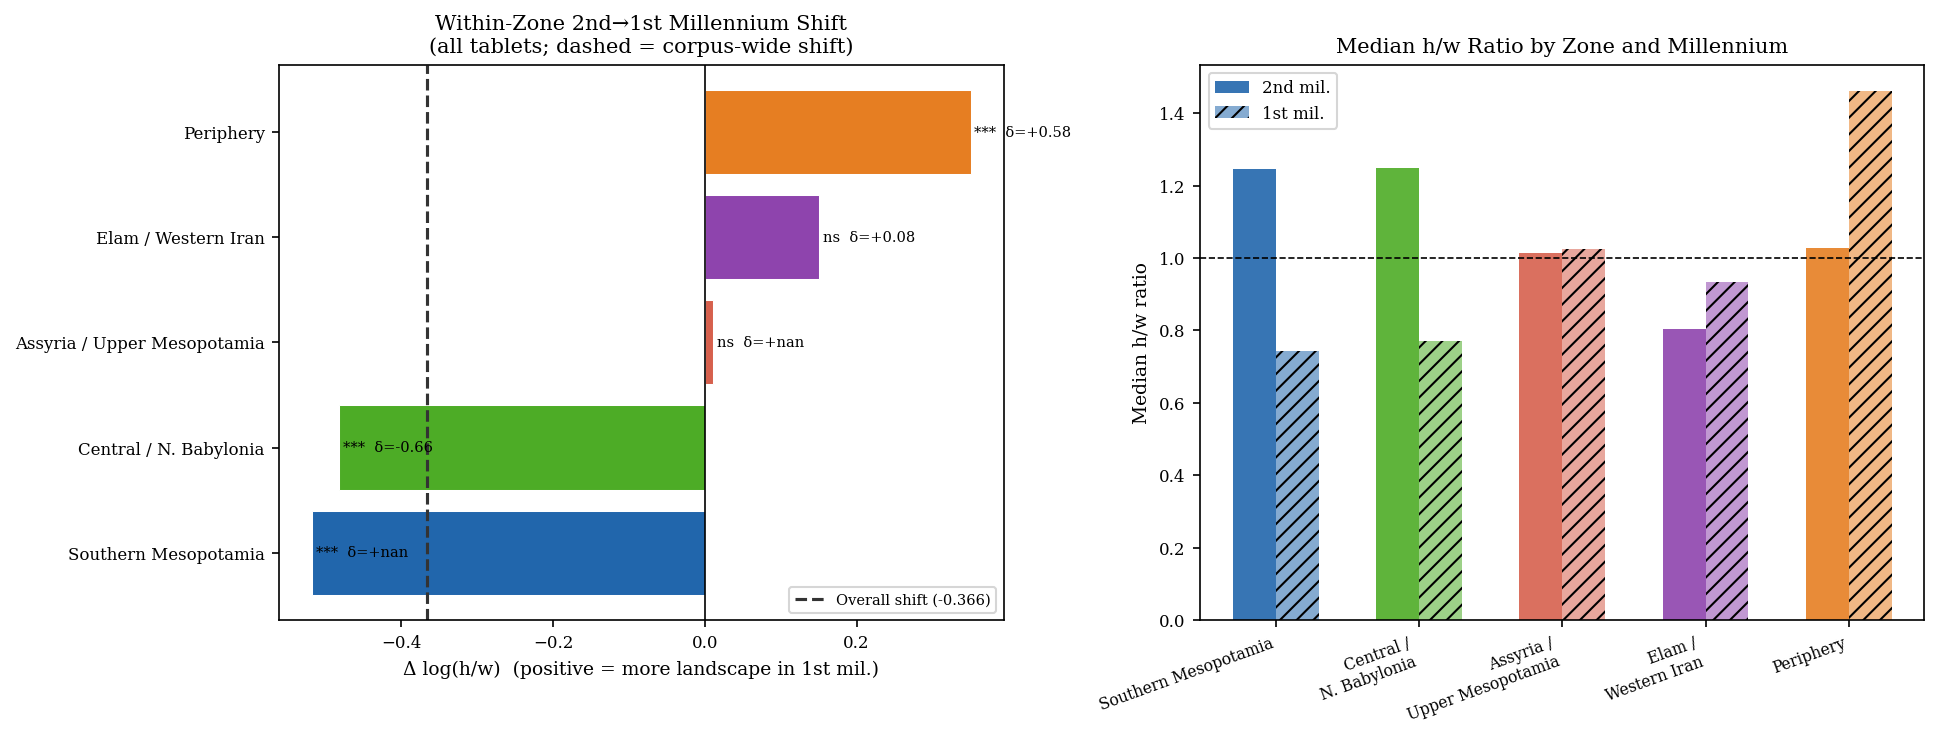

Saved: paper/figures/fig_geo_zone_shift.pdf

Decomposition: 46.4% within-zone, 53.6% compositional


In [6]:
# Figure: zone-level shift plot with overall bar
fig, (ax_shift, ax_ratio) = plt.subplots(1, 2, figsize=(13, 5))

# Left: shift magnitude per zone
zones_present = [z for z in ZONE_ORDER if z in zone_stats]
shifts = [zone_stats[z]['shift'] for z in zones_present]
cols   = [ZONE_COLORS[z] for z in zones_present]

bars = ax_shift.barh(zones_present, shifts, color=cols, edgecolor='white', lw=0.5)
ax_shift.axvline(0, color='black', lw=0.8)
ax_shift.axvline(overall_shift, color='#333333', ls='--', lw=1.5,
                 label=f'Overall shift ({overall_shift:+.3f})')
for bar, zone in zip(bars, zones_present):
    z = zone_stats[zone]
    ax_shift.text(bar.get_width() + 0.005,
                  bar.get_y() + bar.get_height()/2,
                  f"{z['sig']}  δ={z['cliffs_d']:+.2f}",
                  va='center', fontsize=7)
ax_shift.set_xlabel('Δ log(h/w)  (positive = more landscape in 1st mil.)')
ax_shift.set_title('Within-Zone 2nd→1st Millennium Shift\n(all tablets; dashed = corpus-wide shift)')
ax_shift.legend(fontsize=7)

# Right: paired median ratios per zone
x = np.arange(len(zones_present))
w = 0.3
ax_ratio.bar(x - w/2,
             [np.exp(zone_stats[z]['med_2nd']) for z in zones_present],
             w, color=[ZONE_COLORS[z] for z in zones_present], alpha=0.9, label='2nd mil.', hatch='')
ax_ratio.bar(x + w/2,
             [np.exp(zone_stats[z]['med_1st']) for z in zones_present],
             w, color=[ZONE_COLORS[z] for z in zones_present], alpha=0.55, label='1st mil.', hatch='///')
ax_ratio.axhline(1, color='black', ls='--', lw=0.8)
ax_ratio.set_xticks(x)
ax_ratio.set_xticklabels([z.replace(' / ',' /\n') for z in zones_present], fontsize=7.5, ha='right', rotation=20)
ax_ratio.set_ylabel('Median h/w ratio')
ax_ratio.set_title('Median h/w Ratio by Zone and Millennium')
ax_ratio.legend(fontsize=8)

plt.tight_layout()
outpath = f'{FIGURES_DIR}/fig_geo_zone_shift.pdf'
plt.savefig(outpath, bbox_inches='tight')
plt.show()
print(f'Saved: {outpath}')
print(f'\nDecomposition: {within/overall_shift*100:.1f}% within-zone, {compositional/overall_shift*100:.1f}% compositional')

## 5. Layer 2 — Genre-controlled within-zone comparison

Repeats the zone comparison restricted to **Administrative tablets only**.
This controls for the 1st-millennium genre expansion (astronomical, literary
tablets which tend toward landscape format), testing whether the shape shift
occurs within the bureaucratic scribal tradition independently of genre change.

In [7]:
df_adm = df_z[df_z['Genre_Name'] == 'Administrative'].copy()
print(f'Administrative tablets in analysis: {len(df_adm):,}')
print()
print('Administrative zone × millennium counts:')
print(df_adm.groupby(['zone','millennium']).size().unstack(fill_value=0).reindex(ZONE_ORDER).to_string())

adm_stats = {}
for zone in ZONE_ORDER:
    sub2 = df_adm[(df_adm['zone']==zone) & (df_adm['millennium']=='2nd')]['log_ratio'].values
    sub1 = df_adm[(df_adm['zone']==zone) & (df_adm['millennium']=='1st')]['log_ratio'].values
    if len(sub2) >= 10 and len(sub1) >= 10:
        med2, med1 = np.median(sub2), np.median(sub1)
        _, p = mannwhitneyu(sub2, sub1, alternative='two-sided')
        d = ((np.sum(sub1[:,None]>sub2[None,:]) - np.sum(sub1[:,None]<sub2[None,:]))
             / (len(sub1)*len(sub2)))
        sig = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
        adm_stats[zone] = {'med_2nd': med2, 'med_1st': med1,
                           'shift': med1-med2, 'n_2nd': len(sub2), 'n_1st': len(sub1),
                           'cliffs_d': d, 'sig': sig}
        print(f'{zone:35s}  2nd n={len(sub2):4d}  1st n={len(sub1):4d}  '
              f'shift={med1-med2:+.3f}  δ={d:+.3f}  {sig}')
    else:
        print(f'{zone:35s}  insufficient data (2nd n={len(sub2)}, 1st n={len(sub1)})')

Administrative tablets in analysis: 10,116

Administrative zone × millennium counts:
millennium                    1st   2nd
zone                                   
Southern Mesopotamia         4918  1509
Central / N. Babylonia       1040   312
Assyria / Upper Mesopotamia   221  1246
Elam / Western Iran             4   451
Periphery                       3   412
Southern Mesopotamia                 2nd n=1509  1st n=4918  shift=-0.452  δ=-0.633  ***
Central / N. Babylonia               2nd n= 312  1st n=1040  shift=-0.499  δ=-0.702  ***
Assyria / Upper Mesopotamia          2nd n=1246  1st n= 221  shift=+0.583  δ=+0.355  ***
Elam / Western Iran                  insufficient data (2nd n=451, 1st n=4)
Periphery                            insufficient data (2nd n=412, 1st n=3)


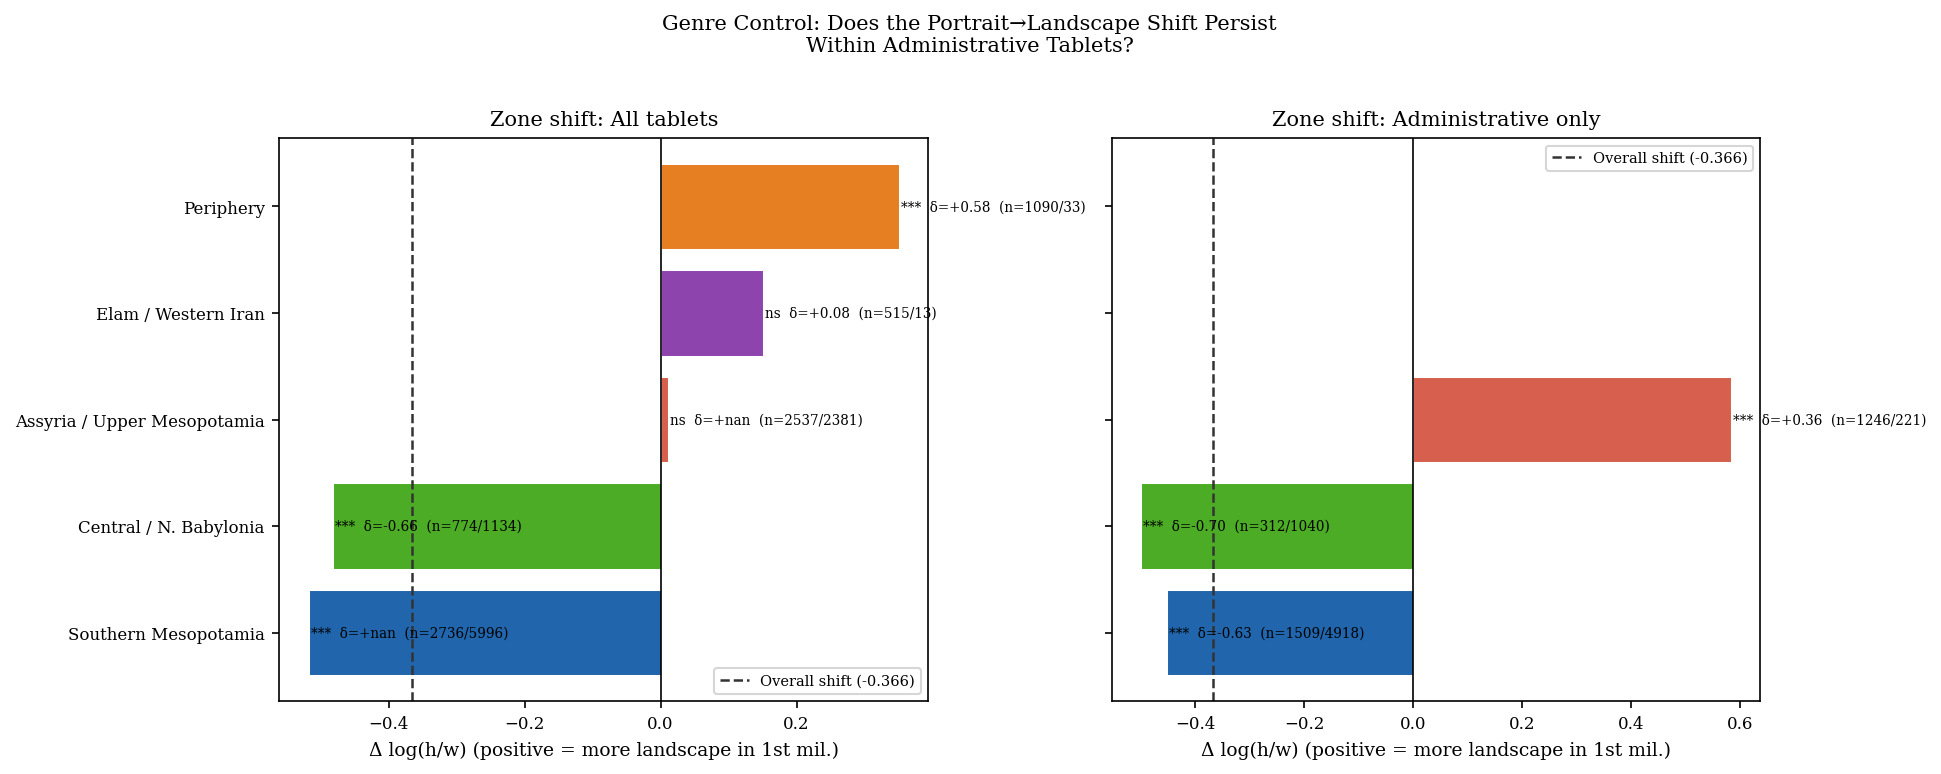

Saved: paper/figures/fig_geo_zone_genre_control.pdf


In [8]:
# Comparison figure: All tablets vs. Administrative only, side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, stats_dict, label in [
    (axes[0], zone_stats,  'All tablets'),
    (axes[1], adm_stats,   'Administrative only'),
]:
    zones_here = [z for z in ZONE_ORDER if z in stats_dict]
    shifts_here = [stats_dict[z]['shift'] for z in zones_here]
    cols_here   = [ZONE_COLORS[z] for z in zones_here]
    bars = ax.barh(zones_here, shifts_here, color=cols_here, edgecolor='white', lw=0.5)
    ax.axvline(0, color='black', lw=0.8)
    ax.axvline(overall_shift, color='#333333', ls='--', lw=1.2,
               label=f'Overall shift ({overall_shift:+.3f})')
    for bar, zone in zip(bars, zones_here):
        z = stats_dict[zone]
        ax.text(bar.get_width() + 0.003,
                bar.get_y() + bar.get_height()/2,
                f"{z['sig']}  δ={z['cliffs_d']:+.2f}  "
                f"(n={z['n_2nd']}/{z['n_1st']})",
                va='center', fontsize=6.5)
    ax.set_xlabel('Δ log(h/w) (positive = more landscape in 1st mil.)')
    ax.set_title(f'Zone shift: {label}')
    ax.legend(fontsize=7)

plt.suptitle('Genre Control: Does the Portrait→Landscape Shift Persist\nWithin Administrative Tablets?',
             fontsize=10, y=1.02)
plt.tight_layout()
outpath = f'{FIGURES_DIR}/fig_geo_zone_genre_control.pdf'
plt.savefig(outpath, bbox_inches='tight')
plt.show()
print(f'Saved: {outpath}')

## 6. Layer 3 — VAE region × millennium trajectories

For each region × millennium cell with N ≥ 30, compute the mean VAE vector.
Plot each region's 2nd→1st millennium trajectory as an arrow in the
η² vs. |ρ| space established in notebook 2.4.
Also compute pairwise Euclidean distances to show which regions changed most
in full shape space.

In [9]:
# Load VAE encodings and join to artifact metadata via CDLI_id / artifact_id
print('Loading VAE encodings from Zenodo...')
vae_dfs = [pd.read_csv(f'{ZENODO_BASE}/vae_encoding_df_April16_w_class_{s}.csv')
           for s in ['train','val','test']]
vae_all = pd.concat(vae_dfs, ignore_index=True)

# CDLI_id in VAE data is integer artifact_id (P-number without 'P' prefix)
vae_all['artifact_id'] = pd.to_numeric(vae_all['CDLI_id'], errors='coerce')
print(f'VAE encodings: {len(vae_all):,} rows')
print(f'VAE CDLI_id sample: {vae_all["CDLI_id"].head(5).tolist()}')

# Join provenience/zone from df_raw onto VAE data
meta_cols = ['artifact_id','ancient_name','cdli_region','zone','millennium','Genre_Name']
meta = df_raw[meta_cols].dropna(subset=['artifact_id'])
meta['artifact_id'] = meta['artifact_id'].astype(int)

vae_geo = vae_all.merge(meta, on='artifact_id', how='inner')
vae_geo = vae_geo[
    vae_geo['zone'].notna() &
    vae_geo['millennium'].notna()
].copy()

print(f'VAE encodings with zone assignment: {len(vae_geo):,}')
print()
print('Zone × millennium VAE counts:')
print(vae_geo.groupby(['zone','millennium']).size().unstack(fill_value=0).reindex(ZONE_ORDER).to_string())

Loading VAE encodings from Zenodo...
VAE encodings: 92,876 rows
VAE CDLI_id sample: [100002, 100004, 100005, 100014, 100023]
VAE encodings with zone assignment: 48,849

Zone × millennium VAE counts:
millennium                     1st    2nd
zone                                     
Southern Mesopotamia          3229  14907
Central / N. Babylonia         347   3091
Assyria / Upper Mesopotamia  22859   2304
Elam / Western Iran            282    121
Periphery                        0   1709


In [10]:
# Load dimension stats from notebook 2.4 for the scatterplot axes
try:
    dim_stats = pd.read_csv(f'{FIGURES_DIR}/vae_dim_stats.csv', index_col='Dimension')
    HW_ETA2 = 0.1272
    HW_RHO  = 0.7327
except FileNotFoundError:
    print('WARNING: vae_dim_stats.csv not found — run notebook 2.4 first.')
    dim_stats = None

# Compute zone × millennium mean VAE vectors
NMIN = 30
zone_mil_means = {}   # (zone, mil) -> array
for zone in ZONE_ORDER:
    for mil in ['2nd','1st']:
        sub = vae_geo[(vae_geo['zone']==zone) & (vae_geo['millennium']==mil)]
        if len(sub) >= NMIN:
            zone_mil_means[(zone, mil)] = sub[VAE_DIMS].mean().values
            print(f'  {zone:35s}  {mil}: n={len(sub):5d}')
        else:
            print(f'  {zone:35s}  {mil}: n={len(sub):5d}  (< {NMIN}, skip)')

print(f'\nZone × millennium mean vectors computed: {len(zone_mil_means)}')

# Per-zone trajectory: vector from 2nd-mil mean to 1st-mil mean
trajectories = {}   # zone -> (mean_2nd, mean_1st, delta)
for zone in ZONE_ORDER:
    if (zone,'2nd') in zone_mil_means and (zone,'1st') in zone_mil_means:
        m2 = zone_mil_means[(zone,'2nd')]
        m1 = zone_mil_means[(zone,'1st')]
        dist = np.linalg.norm(m1 - m2)
        trajectories[zone] = {'mean_2nd': m2, 'mean_1st': m1,
                              'delta': m1 - m2, 'distance': dist}
        print(f'  {zone:35s}  VAE distance 2nd→1st: {dist:.4f}')

  Southern Mesopotamia                 2nd: n=14907
  Southern Mesopotamia                 1st: n= 3229
  Central / N. Babylonia               2nd: n= 3091
  Central / N. Babylonia               1st: n=  347
  Assyria / Upper Mesopotamia          2nd: n= 2304
  Assyria / Upper Mesopotamia          1st: n=22859
  Elam / Western Iran                  2nd: n=  121
  Elam / Western Iran                  1st: n=  282
  Periphery                            2nd: n= 1709
  Periphery                            1st: n=    0  (< 30, skip)

Zone × millennium mean vectors computed: 9
  Southern Mesopotamia                 VAE distance 2nd→1st: 2.7452
  Central / N. Babylonia               VAE distance 2nd→1st: 2.6844
  Assyria / Upper Mesopotamia          VAE distance 2nd→1st: 4.7815
  Elam / Western Iran                  VAE distance 2nd→1st: 4.1282


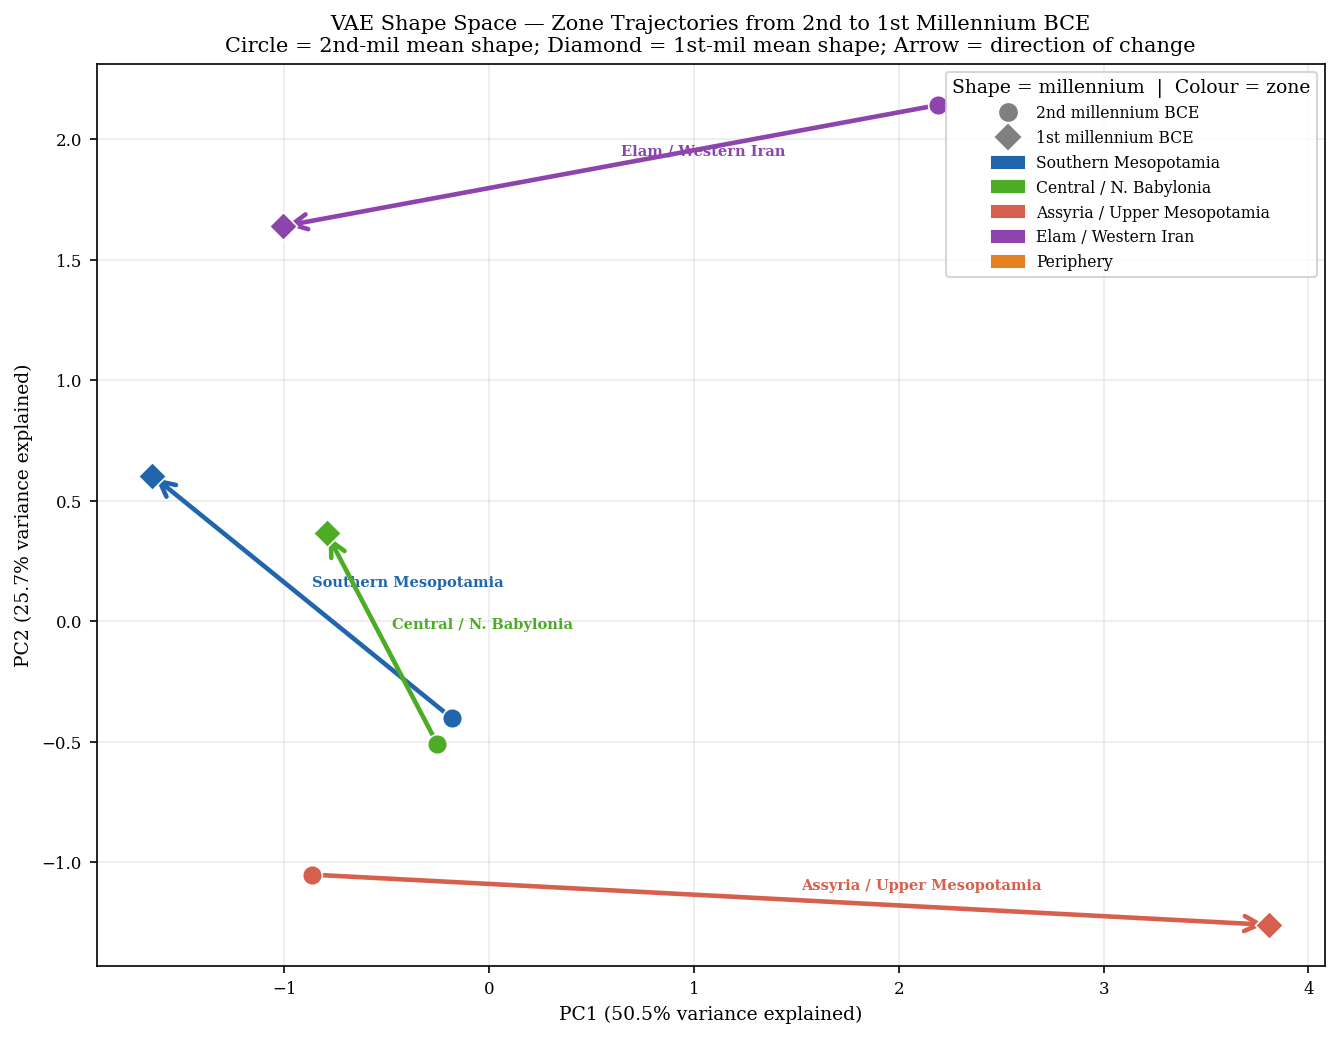

Saved: paper/figures/fig_geo_vae_pca_arrows.pdf


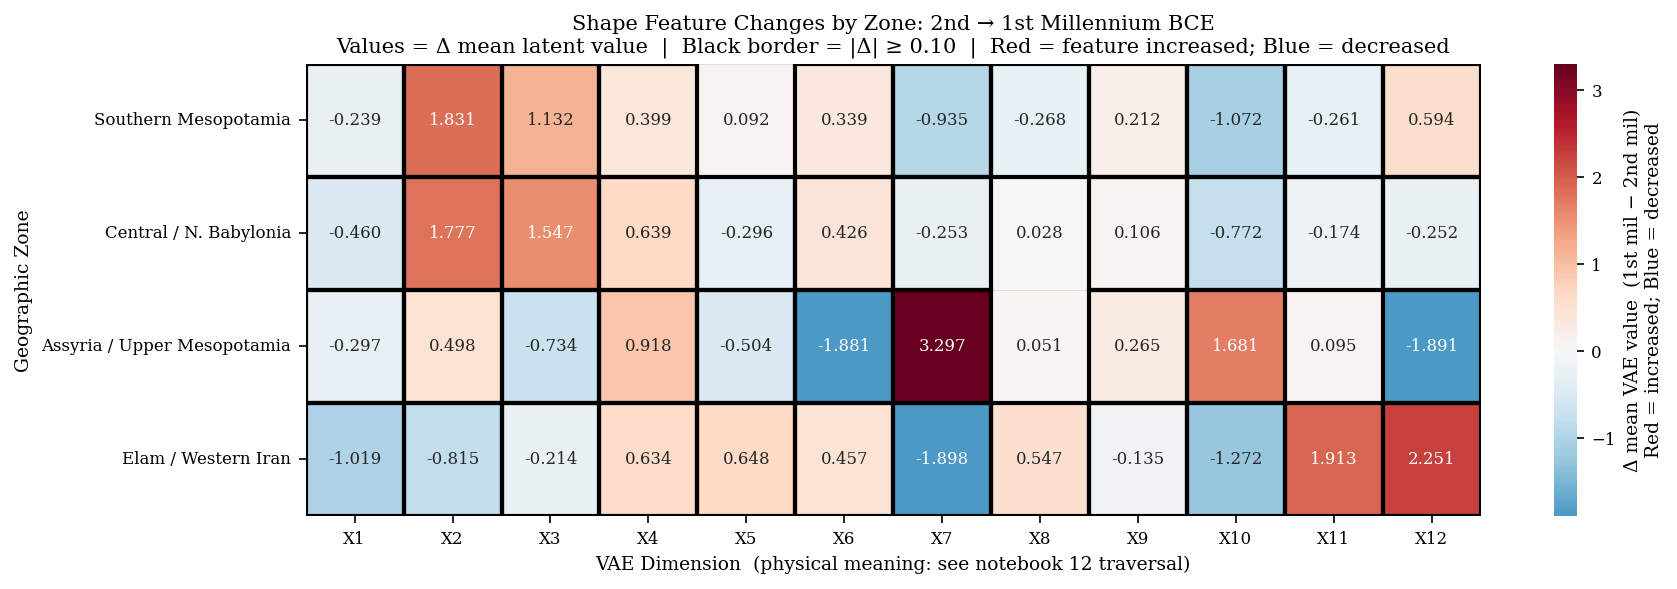

Saved: paper/figures/fig_geo_vae_delta_heatmap.pdf


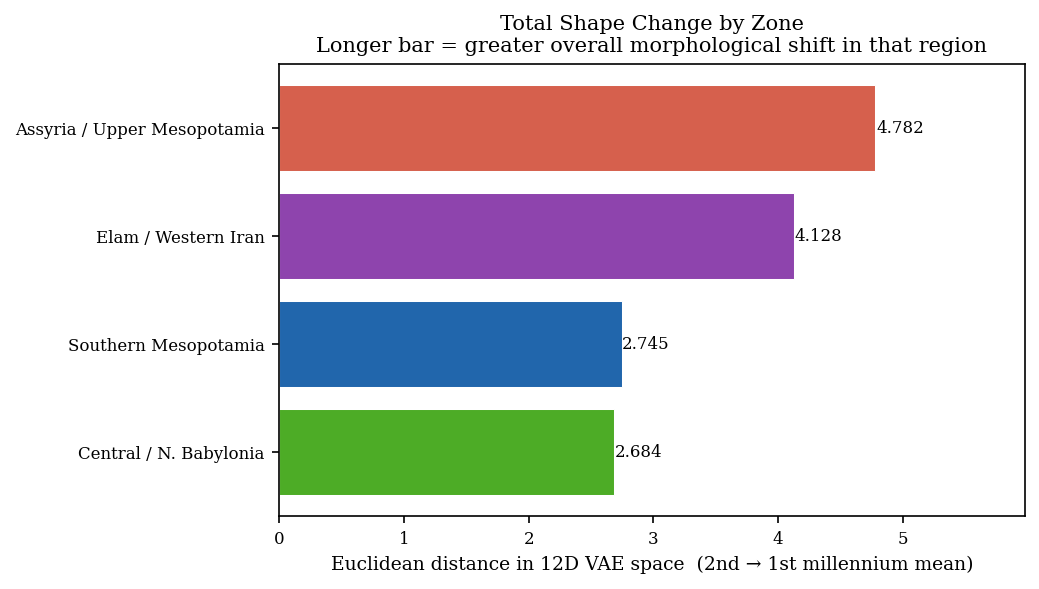

Saved: paper/figures/fig_geo_vae_zone_distances.pdf


In [11]:
if trajectories and dim_stats is not None:

    # ── Figure A: PCA arrow plot ─────────────────────────────────────────────
    # Project ALL zone × millennium mean vectors into 2D via PCA.
    # Each zone then has a unique location in PC space; arrows connect
    # 2nd-mil → 1st-mil for each zone without any overlap.

    from sklearn.decomposition import PCA

    # Stack all vectors: (zone, mil) pairs
    labels_pca, vecs_pca = [], []
    for zone in ZONE_ORDER:
        for mil in ['2nd', '1st']:
            if (zone, mil) in zone_mil_means:
                labels_pca.append((zone, mil))
                vecs_pca.append(zone_mil_means[(zone, mil)])

    pca = PCA(n_components=2)
    coords = pca.fit_transform(np.array(vecs_pca))
    var_exp = pca.explained_variance_ratio_ * 100

    coord_map = {lbl: coords[i] for i, lbl in enumerate(labels_pca)}

    fig, ax = plt.subplots(figsize=(9, 7))

    for zone in ZONE_ORDER:
        if (zone, '2nd') not in coord_map or (zone, '1st') not in coord_map:
            continue
        xy2 = coord_map[(zone, '2nd')]
        xy1 = coord_map[(zone, '1st')]
        col = ZONE_COLORS[zone]

        # Draw arrow 2nd → 1st
        ax.annotate(
            '', xy=xy1, xytext=xy2,
            arrowprops=dict(arrowstyle='->', color=col, lw=2.2,
                            mutation_scale=18)
        )
        # Dot at 2nd-mil position
        ax.scatter(*xy2, color=col, s=90, zorder=5, marker='o',
                   edgecolors='white', lw=0.8)
        # Dot at 1st-mil position
        ax.scatter(*xy1, color=col, s=90, zorder=5, marker='D',
                   edgecolors='white', lw=0.8)

        # Label placed near midpoint, offset slightly
        mid = (xy2 + xy1) / 2
        ax.annotate(zone, mid, fontsize=7, color=col, fontweight='bold',
                    xytext=(5, 5), textcoords='offset points')

    # Legend for marker shapes
    handles_shape = [
        Line2D([0],[0], marker='o', color='gray', ms=8, ls='', label='2nd millennium BCE'),
        Line2D([0],[0], marker='D', color='gray', ms=8, ls='', label='1st millennium BCE'),
    ]
    zone_handles = [mpatches.Patch(color=ZONE_COLORS[z], label=z)
                    for z in ZONE_ORDER if any(z == lbl[0] for lbl in labels_pca)]
    ax.legend(handles=handles_shape + zone_handles, fontsize=7.5, loc='best',
              title='Shape = millennium  |  Colour = zone')

    ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}% variance explained)', fontsize=9)
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}% variance explained)', fontsize=9)
    ax.set_title(
        'VAE Shape Space — Zone Trajectories from 2nd to 1st Millennium BCE\n'
        'Circle = 2nd-mil mean shape; Diamond = 1st-mil mean shape; '
        'Arrow = direction of change',
        fontsize=10
    )
    ax.grid(alpha=0.25)
    plt.tight_layout()
    outpath = f'{FIGURES_DIR}/fig_geo_vae_pca_arrows.pdf'
    plt.savefig(outpath, bbox_inches='tight')
    plt.show()
    print(f'Saved: {outpath}')

    # ── Figure B: Delta heatmap ──────────────────────────────────────────────
    # For each zone × VAE dimension: value = mean_1st - mean_2nd
    # This is the most direct answer to "which shape feature changed where"

    delta_rows, delta_index = [], []
    for zone in ZONE_ORDER:
        if zone in trajectories:
            delta_rows.append(trajectories[zone]['delta'])
            delta_index.append(zone)

    delta_df = pd.DataFrame(delta_rows, index=delta_index, columns=VAE_DIMS)

    # Annotate with significance: per zone × dim, Mann-Whitney on individual tablets
    # (computationally expensive — use a simple marker based on |delta| magnitude)
    DELTA_THRESH = 0.1   # rough "notable change" threshold in latent units

    fig, ax = plt.subplots(figsize=(12, max(4, len(delta_index) * 0.8)))
    im = sns.heatmap(
        delta_df, ax=ax,
        cmap='RdBu_r', center=0,
        annot=True, fmt='.3f', annot_kws={'size': 8},
        linewidths=0.4, linecolor='#e0e0e0',
        cbar_kws={'label': 'Δ mean VAE value  (1st mil − 2nd mil)\n'
                           'Red = increased; Blue = decreased'}
    )

    # Bold annotation for large changes
    for i, zone in enumerate(delta_index):
        for j, dim in enumerate(VAE_DIMS):
            val = delta_df.loc[zone, dim]
            if abs(val) >= DELTA_THRESH:
                ax.add_patch(plt.Rectangle((j, i), 1, 1,
                             fill=False, edgecolor='black', lw=2))

    ax.set_xlabel('VAE Dimension  (physical meaning: see notebook 12 traversal)', fontsize=9)
    ax.set_ylabel('Geographic Zone', fontsize=9)
    ax.set_title(
        'Shape Feature Changes by Zone: 2nd → 1st Millennium BCE\n'
        'Values = Δ mean latent value  |  Black border = |Δ| ≥ 0.10  |  '
        'Red = feature increased; Blue = decreased',
        fontsize=10
    )
    plt.tight_layout()
    outpath = f'{FIGURES_DIR}/fig_geo_vae_delta_heatmap.pdf'
    plt.savefig(outpath, bbox_inches='tight')
    plt.show()
    print(f'Saved: {outpath}')

    # ── Figure C: Zone distance ranking ─────────────────────────────────────
    fig, ax = plt.subplots(figsize=(7, 4))
    dist_data = sorted([(z, v['distance']) for z, v in trajectories.items()],
                       key=lambda x: x[1])
    zones_d = [z for z, _ in dist_data]
    dists_d = [d for _, d in dist_data]
    cols_d  = [ZONE_COLORS[z] for z in zones_d]
    bars = ax.barh(zones_d, dists_d, color=cols_d, edgecolor='white', lw=0.5)
    for bar, d in zip(bars, dists_d):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                f'{d:.3f}', va='center', fontsize=8)
    ax.set_xlabel('Euclidean distance in 12D VAE space  (2nd → 1st millennium mean)')
    ax.set_title('Total Shape Change by Zone\n'
                 'Longer bar = greater overall morphological shift in that region')
    ax.set_xlim(0, max(dists_d) * 1.25)
    plt.tight_layout()
    outpath = f'{FIGURES_DIR}/fig_geo_vae_zone_distances.pdf'
    plt.savefig(outpath, bbox_inches='tight')
    plt.show()
    print(f'Saved: {outpath}')

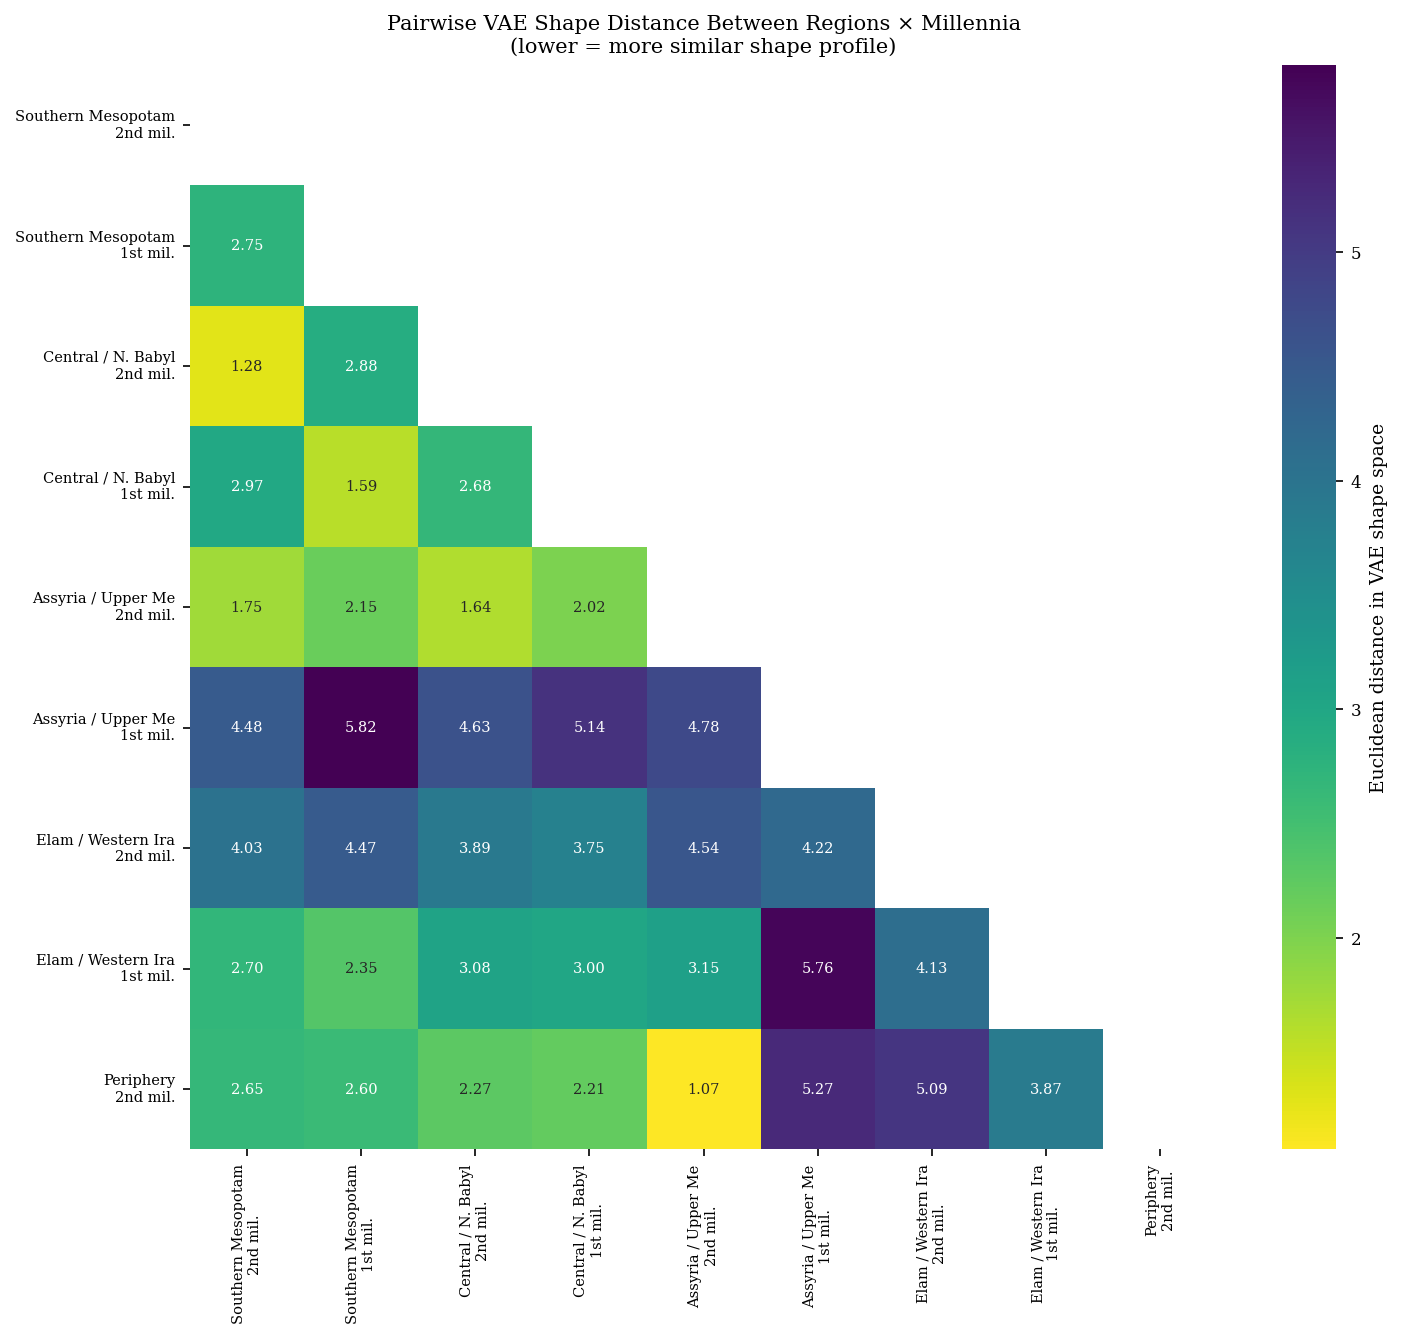

Saved: paper/figures/fig_geo_vae_distance_matrix.pdf

Per-zone VAE shape change 2nd→1st millennium (Euclidean distance):
  Assyria / Upper Mesopotamia          distance=4.7815
  Elam / Western Iran                  distance=4.1282
  Southern Mesopotamia                 distance=2.7452
  Central / N. Babylonia               distance=2.6844


In [12]:
# Euclidean distance heatmap between all zone × millennium mean vectors
if trajectories:
    labels_ordered = []
    vecs_ordered   = []
    for zone in ZONE_ORDER:
        for mil in ['2nd','1st']:
            if (zone, mil) in zone_mil_means:
                labels_ordered.append(f'{zone[:18]}\n{mil} mil.')
                vecs_ordered.append(zone_mil_means[(zone, mil)])

    dist_mat = squareform(pdist(np.array(vecs_ordered), metric='euclidean'))
    dist_df  = pd.DataFrame(dist_mat, index=labels_ordered, columns=labels_ordered)

    fig, ax = plt.subplots(figsize=(10, 9))
    mask = np.triu(np.ones(dist_mat.shape, dtype=bool))
    sns.heatmap(dist_df, mask=mask, cmap='viridis_r', ax=ax,
                annot=True, fmt='.2f', annot_kws={'size': 7},
                cbar_kws={'label': 'Euclidean distance in VAE shape space'})
    ax.set_title('Pairwise VAE Shape Distance Between Regions × Millennia\n'
                 '(lower = more similar shape profile)')
    ax.tick_params(labelsize=7)
    plt.tight_layout()
    outpath = f'{FIGURES_DIR}/fig_geo_vae_distance_matrix.pdf'
    plt.savefig(outpath, bbox_inches='tight')
    plt.show()
    print(f'Saved: {outpath}')

    # Print per-zone 2nd→1st distance ranking
    print('\nPer-zone VAE shape change 2nd→1st millennium (Euclidean distance):')
    dists = [(z, v['distance']) for z, v in trajectories.items()]
    for z, d in sorted(dists, key=lambda x: -x[1]):
        print(f'  {z:35s}  distance={d:.4f}')

## 6b. Map visualization — Geographic distribution of the shape shift

Two paired maps of the cuneiform world showing median h/w ratio per site
for the 2nd versus 1st millennium BCE. Circle size = number of tablets;
circle colour = median h/w ratio (blue = portrait, red = landscape);
sites present in both millennia are shown in both panels for direct comparison.

A site-level shift map (single panel) shows the *direction* of change:
upward-pointing triangle = became more landscape; downward = became more portrait;
circle = no significant change. This makes the spatial pattern of change
immediately legible without reference to numerical axes.

In [13]:
import geopandas as gpd
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.colors as mcolors

# ── Site coordinates (approximate, cuneiform world) ─────────────────────────
# Latitude/longitude for all major sites in the 2nd–1st mil corpus.
# Source: standard historical-geographic references (Roaf 1990; Pleiades).
SITE_COORDS = {
    'Uruk':                  (31.32, 45.64),
    'Nippur':                (32.12, 45.23),
    'Girsu':                 (31.62, 46.17),
    'Umma':                  (31.73, 45.70),
    'Ur':                    (30.96, 46.10),
    'Larsa':                 (31.28, 45.86),
    'Isin':                  (31.88, 45.28),
    'Sippar-Yahrurum':       (33.38, 44.29),
    'Babylon':               (32.54, 44.42),
    'Kish':                  (32.56, 44.65),
    'Borsippa':              (32.39, 44.34),
    'Nineveh':               (36.36, 43.15),
    'Assur':                 (35.46, 43.26),
    'Kalhu':                 (36.10, 43.33),
    'Gasur/Nuzi':            (35.52, 44.24),
    'Kanesh':                (38.84, 35.63),
    'Ḫattusa':               (40.02, 34.62),
    'Susa':                  (32.19, 48.26),
    'Kabnak':                (32.53, 48.56),
    'Pārśa':                 (29.94, 52.89),
    'Mari':                  (34.55, 40.89),
    'Ebla':                  (35.80, 36.80),
    'Puzriš-Dagan':          (32.12, 45.23),   # near Nippur
    'Dur-Šarrukin':          (36.51, 43.23),
    'Huzirina':              (37.22, 38.71),
    'Adab':                  (31.99, 45.55),
    'Irisagrig':             (31.80, 45.40),   # approximate
    'Ešnunna':               (33.72, 44.84),
    'Dūr-Abī-ēšuḫ':         (32.30, 45.60),   # approximate, Babylonia
    'Pī-Kasî':               (32.90, 44.50),   # approximate, Babylonia
    'Tuttul':                (36.00, 39.01),
    'Šibaniba':              (36.10, 43.70),   # approximate, Assyria
    'Ālu-ša-Našar':          (33.00, 44.30),   # approximate
    'Yāhūdu':                (32.50, 44.60),   # approximate, Babylonia
    'Dur-Untaš':             (32.00, 48.70),   # approximate, Elam
    'Ugarit':                (35.60, 35.78),
    'Alalakh':               (36.24, 36.52),
    'Emar':                  (36.74, 39.68),
    'Dilbat':                (32.33, 44.43),
    'Lagaba':                (33.00, 44.40),   # approximate
    'Shaduppum':             (33.44, 44.48),
    'Nerebtum':              (33.44, 44.70),
    'Shuruppak':             (31.79, 45.50),
}

# ── Compute site-level statistics for 2nd and 1st millennium ────────────────
MIN_N_MAP = 10
site_map_rows = []

for site in df_z['ancient_name'].unique():
    if site not in SITE_COORDS:
        continue
    lat, lon = SITE_COORDS[site]
    for mil in ['2nd', '1st']:
        sub = df_z[(df_z['ancient_name']==site) & (df_z['millennium']==mil)]
        if len(sub) < MIN_N_MAP:
            continue
        zone = df_z[df_z['ancient_name']==site]['zone'].mode()
        zone = zone.iloc[0] if len(zone) else 'Unknown'
        site_map_rows.append({
            'site': site, 'millennium': mil,
            'lat': lat, 'lon': lon,
            'n': len(sub),
            'median_ratio': np.median(sub['hw_ratio'].values),
            'zone': zone,
        })

map_df = pd.DataFrame(site_map_rows)
print(f'Sites on map: {map_df["site"].nunique()} | '
      f'2nd mil: {(map_df["millennium"]=="2nd").sum()} | '
      f'1st mil: {(map_df["millennium"]=="1st").sum()}')

# Sites present in BOTH millennia (for shift map)
both_sites = (map_df.groupby('site')['millennium']
              .apply(lambda x: set(x.tolist()))
              .pipe(lambda s: s[s.apply(lambda v: {'2nd','1st'}.issubset(v))].index.tolist()))
print(f'Sites with data in both millennia: {len(both_sites)}')
print(both_sites)

Sites on map: 34 | 2nd mil: 30 | 1st mil: 15
Sites with data in both millennia: 11
['Assur', 'Babylon', 'Dilbat', 'Kalhu', 'Kish', 'Larsa', 'Nineveh', 'Nippur', 'Sippar-Yahrurum', 'Ur', 'Uruk']


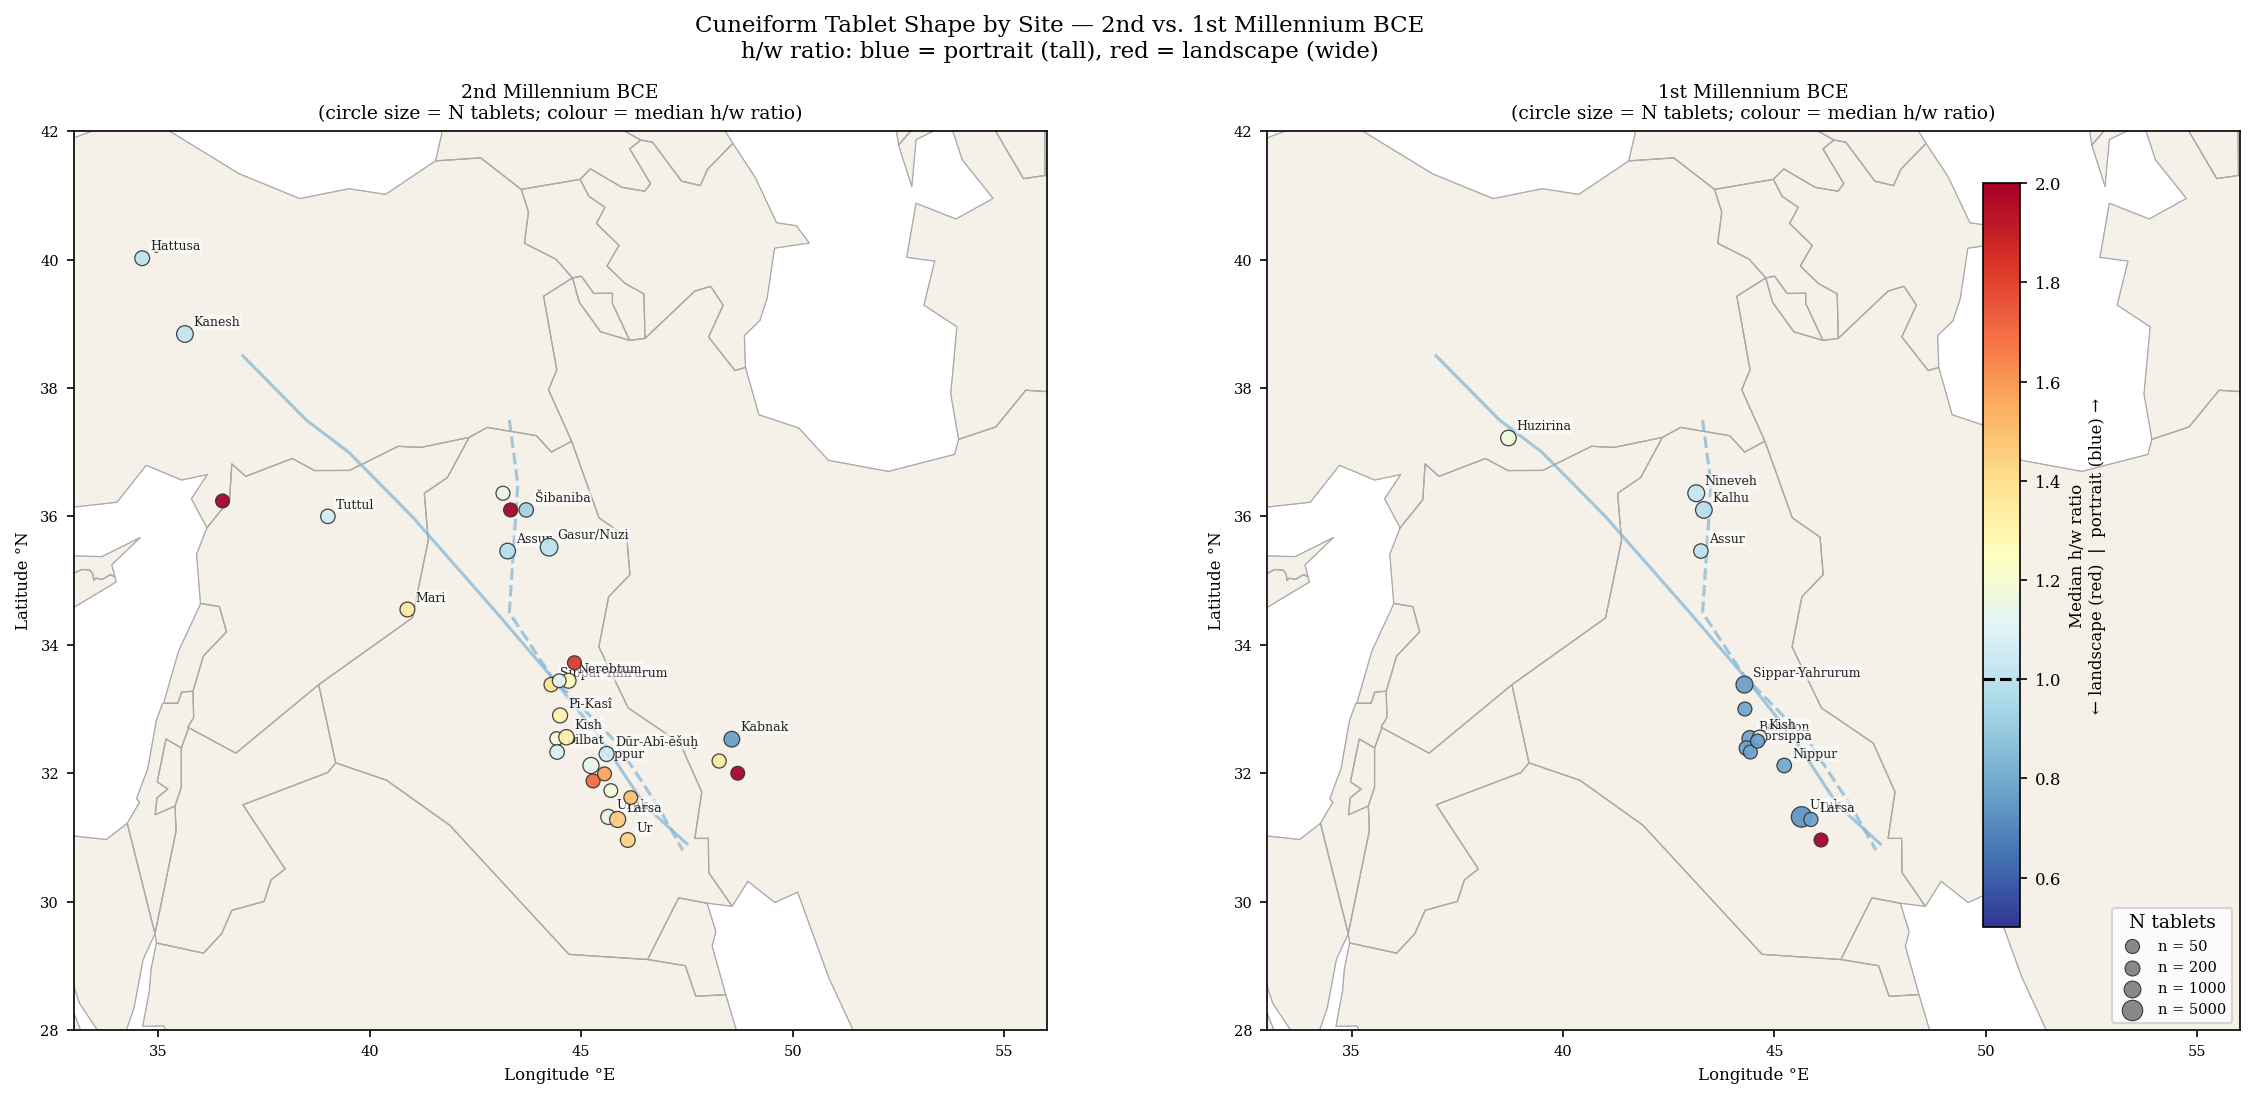

Saved: paper/figures/fig_geo_map_paired.pdf


In [14]:
# Load world map via geopandas (Natural Earth 110m, downloaded locally)
world = gpd.read_file('data/ne_maps/ne_110m_admin_0_countries.shp')

# Clip to cuneiform world bounding box
LON_MIN, LON_MAX = 33, 56
LAT_MIN, LAT_MAX = 28, 42
region_box = world.cx[LON_MIN:LON_MAX, LAT_MIN:LAT_MAX]

# Shared colour scale: h/w ratio, clipped to [0.5, 2.0]
RATIO_MIN, RATIO_MAX = 0.5, 2.0
cmap_ratio  = plt.cm.RdYlBu   # blue = portrait (>1), red = landscape (<1)
norm_ratio  = Normalize(vmin=RATIO_MIN, vmax=RATIO_MAX)
# Reverse: high ratio (portrait) → blue; low ratio (landscape) → red
cmap_ratio  = plt.cm.RdYlBu_r

# Size scale: sqrt of n for visual clarity
def marker_size(n, base=40, scale=0.8):
    return base + scale * np.sqrt(n)

# ── Map 1: paired 2nd / 1st millennium panels ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7),
                         subplot_kw={'aspect': 'equal'})

for ax, mil, title in [
    (axes[0], '2nd', '2nd Millennium BCE'),
    (axes[1], '1st', '1st Millennium BCE'),
]:
    sub = map_df[map_df['millennium'] == mil]

    # Country outlines
    region_box.boundary.plot(ax=ax, color='#aaaaaa', lw=0.6)
    region_box.plot(ax=ax, color='#f5f0e8', edgecolor='#cccccc', lw=0.4)

    # Rivers schematic (Tigris/Euphrates as simple polylines)
    # Euphrates: approximate course
    euph = np.array([[37.0,38.5],[38.5,37.5],[39.5,37.0],[41.0,36.0],
                     [43.0,34.5],[44.3,33.5],[45.5,32.5],[46.5,31.5],[47.5,30.9]])
    tigr = np.array([[43.3,37.5],[43.5,36.5],[43.4,35.5],[43.3,34.5],
                     [44.3,33.5],[45.8,32.5],[46.8,31.5],[47.4,30.8]])
    ax.plot(euph[:,0], euph[:,1], color='#7EB5D6', lw=1.5, alpha=0.7, label='Euphrates')
    ax.plot(tigr[:,0], tigr[:,1], color='#7EB5D6', lw=1.5, alpha=0.7, ls='--')

    # Site bubbles
    sc = ax.scatter(
        sub['lon'], sub['lat'],
        s=[marker_size(n) for n in sub['n']],
        c=sub['median_ratio'].clip(RATIO_MIN, RATIO_MAX),
        cmap=cmap_ratio, norm=norm_ratio,
        edgecolors='#333333', lw=0.6, zorder=5, alpha=0.92
    )

    # Site labels (only for sites with N ≥ 50 to keep legible)
    for _, row in sub[sub['n'] >= 50].iterrows():
        ax.annotate(row['site'], (row['lon'], row['lat']),
                    fontsize=6, xytext=(4, 4), textcoords='offset points',
                    color='#222222',
                    bbox=dict(boxstyle='round,pad=0.1', fc='white', alpha=0.6, ec='none'))

    ax.set_xlim(LON_MIN, LON_MAX)
    ax.set_ylim(LAT_MIN, LAT_MAX)
    ax.set_xlabel('Longitude °E', fontsize=8)
    ax.set_ylabel('Latitude °N', fontsize=8)
    ax.set_title(f'{title}\n(circle size = N tablets; colour = median h/w ratio)', fontsize=9)
    ax.tick_params(labelsize=7)

# Shared colourbar
sm = ScalarMappable(cmap=cmap_ratio, norm=norm_ratio)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, orientation='vertical', fraction=0.02, pad=0.02)
cbar.set_label('Median h/w ratio\n← landscape (red)  |  portrait (blue) →', fontsize=8)
cbar.ax.axhline(1.0, color='black', lw=1.5, ls='--')

# Size legend
size_legend = [
    plt.scatter([], [], s=marker_size(n), c='#888888', edgecolors='#333333', lw=0.5,
                label=f'n = {n}')
    for n in [50, 200, 1000, 5000]
]
axes[1].legend(handles=size_legend, title='N tablets', fontsize=7,
               loc='lower right', scatterpoints=1)

fig.suptitle('Cuneiform Tablet Shape by Site — 2nd vs. 1st Millennium BCE\n'
             'h/w ratio: blue = portrait (tall), red = landscape (wide)',
             fontsize=11, y=1.01)
plt.tight_layout()
outpath = f'{FIGURES_DIR}/fig_geo_map_paired.pdf'
plt.savefig(outpath, bbox_inches='tight', dpi=200)
plt.show()
print(f'Saved: {outpath}')

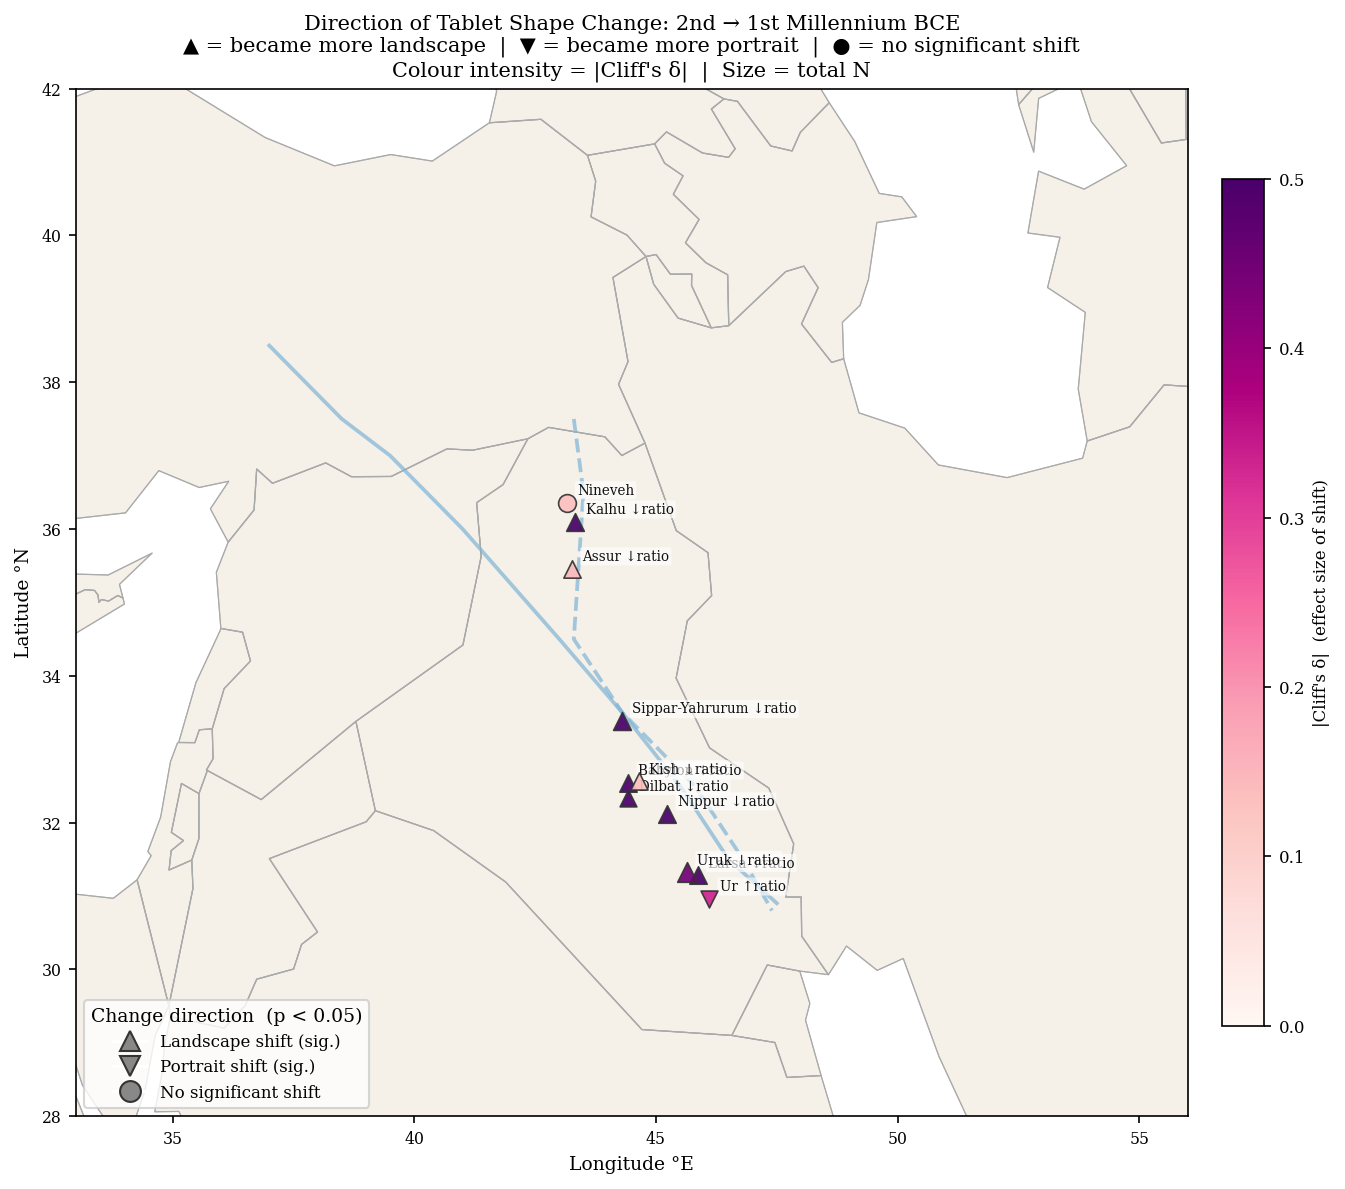

Saved: paper/figures/fig_geo_map_shift.pdf


In [15]:
# ── Map 2: shift direction map (single panel) ────────────────────────────────
# For each site with data in both millennia:
#   triangle up   = became significantly more landscape (Cliff's δ < -0.1, p < 0.05)
#   triangle down = became significantly more portrait  (Cliff's δ > +0.1, p < 0.05)
#   circle        = no significant or small change
# Colour = magnitude of Cliff's δ (|δ|); size = total N across both millennia

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'aspect':'equal'})
region_box.plot(ax=ax, color='#f5f0e8', edgecolor='#bbbbbb', lw=0.5)
region_box.boundary.plot(ax=ax, color='#aaaaaa', lw=0.6)
ax.plot(euph[:,0], euph[:,1], color='#7EB5D6', lw=1.8, alpha=0.7)
ax.plot(tigr[:,0], tigr[:,1], color='#7EB5D6', lw=1.8, alpha=0.7, ls='--')

ALPHA_BONF = 0.05 / max(len(both_sites), 1)
cmap_delta  = plt.cm.RdPu   # light = small change, dark = large change
norm_delta  = Normalize(vmin=0, vmax=0.5)

for site in both_sites:
    row2 = map_df[(map_df['site']==site) & (map_df['millennium']=='2nd')].iloc[0]
    row1 = map_df[(map_df['site']==site) & (map_df['millennium']=='1st')].iloc[0]
    lat, lon = row2['lat'], row2['lon']

    g2 = df_z[(df_z['ancient_name']==site) & (df_z['millennium']=='2nd')]['hw_ratio'].values
    g1 = df_z[(df_z['ancient_name']==site) & (df_z['millennium']=='1st')]['hw_ratio'].values
    _, p_mw = mannwhitneyu(g2, g1, alternative='two-sided')
    cliffs_d = ((np.sum(g1[:,None] > g2[None,:]) - np.sum(g1[:,None] < g2[None,:]))
                / (len(g1) * len(g2)))

    n_total = len(g2) + len(g1)
    sz = marker_size(n_total, base=60, scale=0.4)
    col = cmap_delta(norm_delta(abs(cliffs_d)))

    # Choose marker by direction and significance
    if p_mw < 0.05 and cliffs_d < -0.1:
        marker = '^'   # landscape shift
        label_suffix = f' ↓ratio'
    elif p_mw < 0.05 and cliffs_d > 0.1:
        marker = 'v'   # portrait shift
        label_suffix = f' ↑ratio'
    else:
        marker = 'o'   # no clear shift
        label_suffix = ''

    ax.scatter(lon, lat, s=sz, c=[col], cmap=cmap_delta, norm=norm_delta,
               marker=marker, edgecolors='#333333', lw=0.8, zorder=5, alpha=0.92)
    ax.annotate(
        f'{site}{label_suffix}',
        (lon, lat), fontsize=6.5, xytext=(5, 4), textcoords='offset points',
        color='#111111',
        bbox=dict(boxstyle='round,pad=0.15', fc='white', alpha=0.65, ec='none')
    )

ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_xlabel('Longitude °E', fontsize=9)
ax.set_ylabel('Latitude °N', fontsize=9)
ax.set_title(
    'Direction of Tablet Shape Change: 2nd → 1st Millennium BCE\n'
    '▲ = became more landscape  |  ▼ = became more portrait  |  ● = no significant shift\n'
    'Colour intensity = |Cliff\'s δ|  |  Size = total N',
    fontsize=10
)
ax.tick_params(labelsize=7.5)

# Colourbar for |δ|
sm2 = ScalarMappable(cmap=cmap_delta, norm=norm_delta)
sm2.set_array([])
cbar2 = fig.colorbar(sm2, ax=ax, fraction=0.025, pad=0.02)
cbar2.set_label('|Cliff\'s δ|  (effect size of shift)', fontsize=8)

# Marker legend
marker_handles = [
    Line2D([0],[0], marker='^', color='w', markerfacecolor='#888888',
           markeredgecolor='#333333', ms=10, label='Landscape shift (sig.)'),
    Line2D([0],[0], marker='v', color='w', markerfacecolor='#888888',
           markeredgecolor='#333333', ms=10, label='Portrait shift (sig.)'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#888888',
           markeredgecolor='#333333', ms=10, label='No significant shift'),
]
ax.legend(handles=marker_handles, fontsize=8, loc='lower left',
          title='Change direction  (p < 0.05)')

plt.tight_layout()
outpath = f'{FIGURES_DIR}/fig_geo_map_shift.pdf'
plt.savefig(outpath, bbox_inches='tight', dpi=200)
plt.show()
print(f'Saved: {outpath}')

## 7. Supplementary — Site-level panel

For individual sites with N ≥ 30 in both the 2nd and 1st millennium,
repeat the Layer 1+2 analysis. This identifies which specific cities
drove the trend and which bucked it.

In [16]:
MIN_N_SITE = 30   # minimum tablets per millennium for site-level analysis

site_rows = []
for site in df_z['ancient_name'].unique():
    sub2 = df_z[(df_z['ancient_name']==site) & (df_z['millennium']=='2nd')]['log_ratio'].values
    sub1 = df_z[(df_z['ancient_name']==site) & (df_z['millennium']=='1st')]['log_ratio'].values
    if len(sub2) < MIN_N_SITE or len(sub1) < MIN_N_SITE:
        continue
    _, p = mannwhitneyu(sub2, sub1, alternative='two-sided')
    d = ((np.sum(sub1[:,None]>sub2[None,:]) - np.sum(sub1[:,None]<sub2[None,:]))
         / (len(sub1)*len(sub2)))
    zone = df_z[df_z['ancient_name']==site]['zone'].mode()
    zone = zone.iloc[0] if len(zone) else 'Unknown'
    region = df_z[df_z['ancient_name']==site]['cdli_region'].mode()
    region = region.iloc[0] if len(region) else 'Unknown'
    region_src = df_z[df_z['ancient_name']==site]['region_source'].mode()
    region_src = region_src.iloc[0] if len(region_src) else 'Unknown'
    sig = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
    site_rows.append({
        'Site': site, 'Zone': zone, 'CDLI_Region': region, 'Region_Source': region_src,
        'n_2nd': len(sub2), 'n_1st': len(sub1),
        'median_2nd': round(np.exp(np.median(sub2)), 3),
        'median_1st': round(np.exp(np.median(sub1)), 3),
        'shift_log': round(np.median(sub1)-np.median(sub2), 4),
        'cliffs_d': round(d, 4), 'p_MW': round(p, 6), 'sig': sig
    })

site_df = pd.DataFrame(site_rows).sort_values('shift_log', ascending=False)
print(f'Sites with N≥{MIN_N_SITE} in both millennia: {len(site_df)}')
print()
print(site_df[['Site','Zone','n_2nd','n_1st','median_2nd','median_1st',
               'shift_log','cliffs_d','sig']].to_string(index=False))

# Save as Supplementary Table S-Geo
site_df.to_csv(f'{FIGURES_DIR}/supplementary_table_S_Geo.csv', index=False)
print(f'\nSaved: supplementary_table_S_Geo.csv')

Sites with N≥30 in both millennia: 10

           Site                        Zone  n_2nd  n_1st  median_2nd  median_1st  shift_log  cliffs_d sig
             Ur        Southern Mesopotamia    170     34       1.444       2.000     0.3259    0.3332  **
          Assur Assyria / Upper Mesopotamia    423     97       0.976       1.000     0.0247   -0.1456   *
        Nineveh Assyria / Upper Mesopotamia     37    983       1.143       1.025    -0.1088   -0.1358  ns
           Kish        Southern Mesopotamia    297     96       1.306       1.088    -0.1819   -0.1345   *
         Dilbat        Southern Mesopotamia    111     31       1.077       0.780    -0.3219   -0.5801 ***
         Nippur        Southern Mesopotamia    633    124       1.133       0.788    -0.3628   -0.5338 ***
           Uruk        Southern Mesopotamia    235   4923       1.150       0.733    -0.4499   -0.4479 ***
Sippar-Yahrurum      Central / N. Babylonia     89   1034       1.388       0.768    -0.5921   -0.6996 **

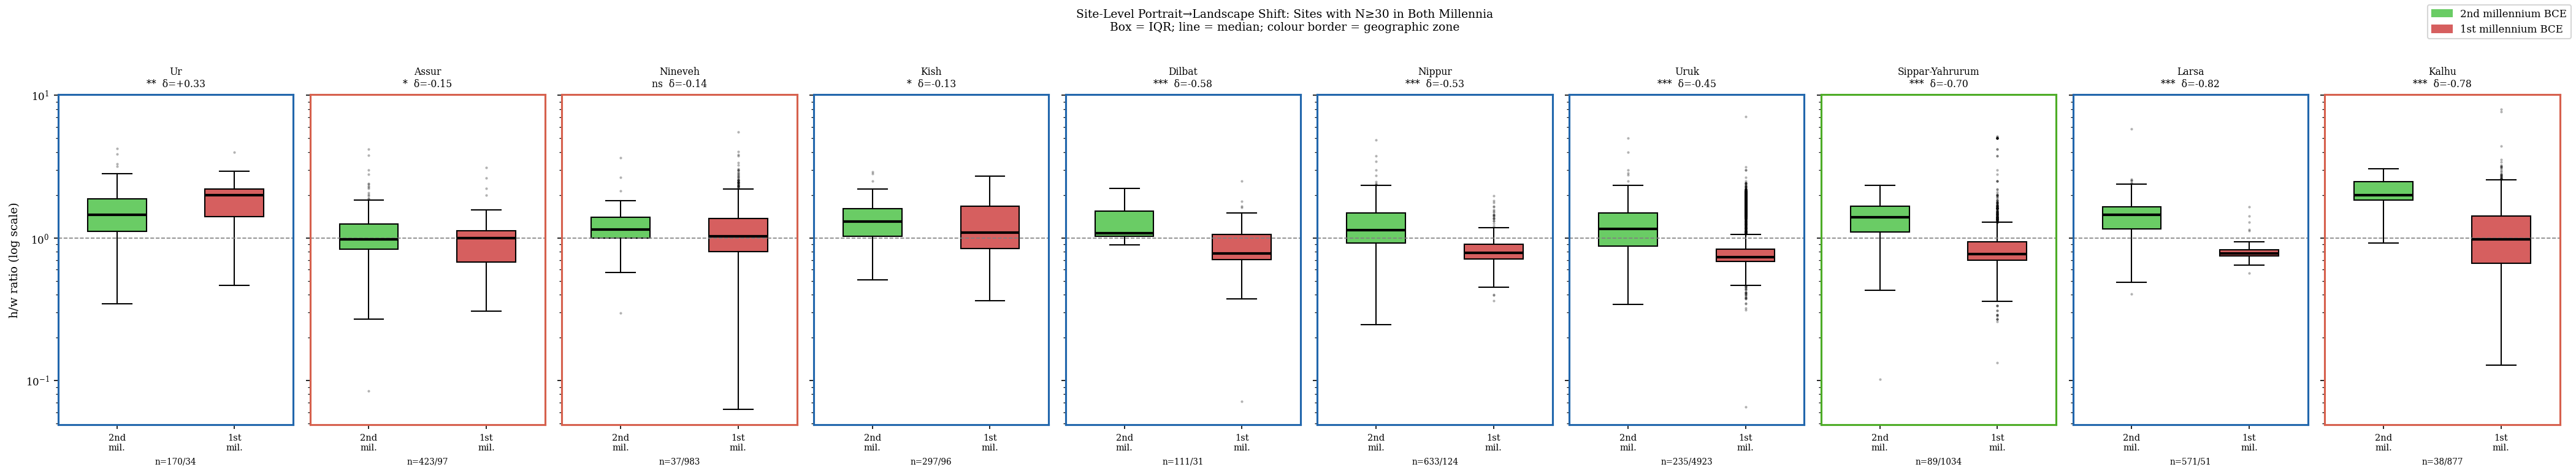

Saved: paper/figures/fig_geo_site_panel.pdf


In [17]:
# Figure: site-level panel (both millennia box plots, one column per site)
sites_for_plot = site_df['Site'].tolist()
n_sites = len(sites_for_plot)

if n_sites > 0:
    fig, axes = plt.subplots(1, n_sites, figsize=(n_sites * 2.8, 5),
                             sharey=True, squeeze=False)
    for ax, site in zip(axes[0], sites_for_plot):
        zone  = site_df.loc[site_df['Site']==site, 'Zone'].iloc[0]
        col   = ZONE_COLORS.get(zone, '#888888')
        row   = site_df[site_df['Site']==site].iloc[0]

        data_2 = df_z[(df_z['ancient_name']==site) & (df_z['millennium']=='2nd')]['hw_ratio'].values
        data_1 = df_z[(df_z['ancient_name']==site) & (df_z['millennium']=='1st')]['hw_ratio'].values

        bp = ax.boxplot([data_2, data_1],
                        positions=[0, 1],
                        widths=0.5,
                        patch_artist=True,
                        medianprops={'color':'black','lw':2},
                        flierprops={'marker':'.','ms':2,'alpha':0.3})
        bp['boxes'][0].set_facecolor(MILLENNIUM_PALETTE['2nd millennium BCE'])
        bp['boxes'][1].set_facecolor(MILLENNIUM_PALETTE['1st millennium BCE'])

        ax.set_xticks([0,1])
        ax.set_xticklabels(['2nd\nmil.','1st\nmil.'], fontsize=7)
        ax.set_yscale('log')
        ax.set_title(f'{site}\n{row["sig"]}  δ={row["cliffs_d"]:+.2f}', fontsize=7.5)
        ax.axhline(1, color='gray', ls='--', lw=0.8)
        for spine in ax.spines.values():
            spine.set_edgecolor(col)
            spine.set_linewidth(1.5)
        ax.set_xlabel(f'n={row["n_2nd"]}/{row["n_1st"]}', fontsize=6.5)

    axes[0][0].set_ylabel('h/w ratio (log scale)')
    fig.suptitle(
        f'Site-Level Portrait→Landscape Shift: Sites with N≥{MIN_N_SITE} in Both Millennia\n'
        'Box = IQR; line = median; colour border = geographic zone',
        fontsize=9, y=1.02
    )
    handles = [mpatches.Patch(color=v, label=k) for k,v in MILLENNIUM_PALETTE.items()]
    fig.legend(handles=handles, loc='upper right', fontsize=8)
    plt.tight_layout()
    outpath = f'{FIGURES_DIR}/fig_geo_site_panel.pdf'
    plt.savefig(outpath, bbox_inches='tight')
    plt.show()
    print(f'Saved: {outpath}')

## 8. Summary

In [18]:
print('=== GEOGRAPHIC ANALYSIS SUMMARY ===')
print()
print('Layer 1 — Variance decomposition:')
print(f'  Overall log-ratio shift (2nd→1st mil): {overall_shift:+.4f}')
print(f'  Within-region component:  {within:+.4f}  ({within/overall_shift*100:.1f}%)')
print(f'  Compositional component:  {compositional:+.4f}  ({compositional/overall_shift*100:.1f}%)')
if within/overall_shift > 0.5:
    print('  INTERPRETATION: Within-region component dominates → trend is real, not a sampling artifact.')
else:
    print('  INTERPRETATION: Compositional component is substantial → Uruk/sampling confound cannot be dismissed.')
print()
print('Layer 1+2 — Zone shifts (all tablets vs. administrative only):')
for zone in ZONE_ORDER:
    all_sig  = zone_stats.get(zone, {}).get('sig', 'n/a')
    adm_sig  = adm_stats.get(zone, {}).get('sig', 'n/a')
    all_d    = zone_stats.get(zone, {}).get('cliffs_d', np.nan)
    adm_d    = adm_stats.get(zone, {}).get('cliffs_d', np.nan)
    print(f'  {zone:35s}  All: {all_sig} δ={all_d:+.3f}  |  Adm: {adm_sig} δ={adm_d:+.3f}')
print()
print('Layer 3 — VAE region distances 2nd→1st mil:')
for z, d in sorted([(z,v["distance"]) for z,v in trajectories.items()], key=lambda x: -x[1]):
    print(f'  {z:35s}  {d:.4f}')
print()
print('Site-level panel:')
print(site_df[['Site','n_2nd','n_1st','cliffs_d','sig']].to_string(index=False))
print()
print('Figures saved:')
import glob as _g
for fn in sorted(_g.glob(f'{FIGURES_DIR}/fig_geo_*.pdf') +
                 [f'{FIGURES_DIR}/supplementary_table_S_Geo.csv']):
    if os.path.exists(fn):
        print(f'  {os.path.basename(fn)}')

=== GEOGRAPHIC ANALYSIS SUMMARY ===

Layer 1 — Variance decomposition:
  Overall log-ratio shift (2nd→1st mil): -0.3664
  Within-region component:  -0.1702  (46.4%)
  Compositional component:  -0.1962  (53.6%)
  INTERPRETATION: Compositional component is substantial → Uruk/sampling confound cannot be dismissed.

Layer 1+2 — Zone shifts (all tablets vs. administrative only):
  Southern Mesopotamia                 All: *** δ=+nan  |  Adm: *** δ=-0.633
  Central / N. Babylonia               All: *** δ=-0.657  |  Adm: *** δ=-0.702
  Assyria / Upper Mesopotamia          All: ns δ=+nan  |  Adm: *** δ=+0.355
  Elam / Western Iran                  All: ns δ=+0.081  |  Adm: n/a δ=+nan
  Periphery                            All: *** δ=+0.584  |  Adm: n/a δ=+nan

Layer 3 — VAE region distances 2nd→1st mil:
  Assyria / Upper Mesopotamia          4.7815
  Elam / Western Iran                  4.1282
  Southern Mesopotamia                 2.7452
  Central / N. Babylonia               2.6844

Site-lev